Componenents:

Causal Multi-Head Self-Attention

Feed-Forward Network (FFN)

Layer Normalization

Residual or Skip connections


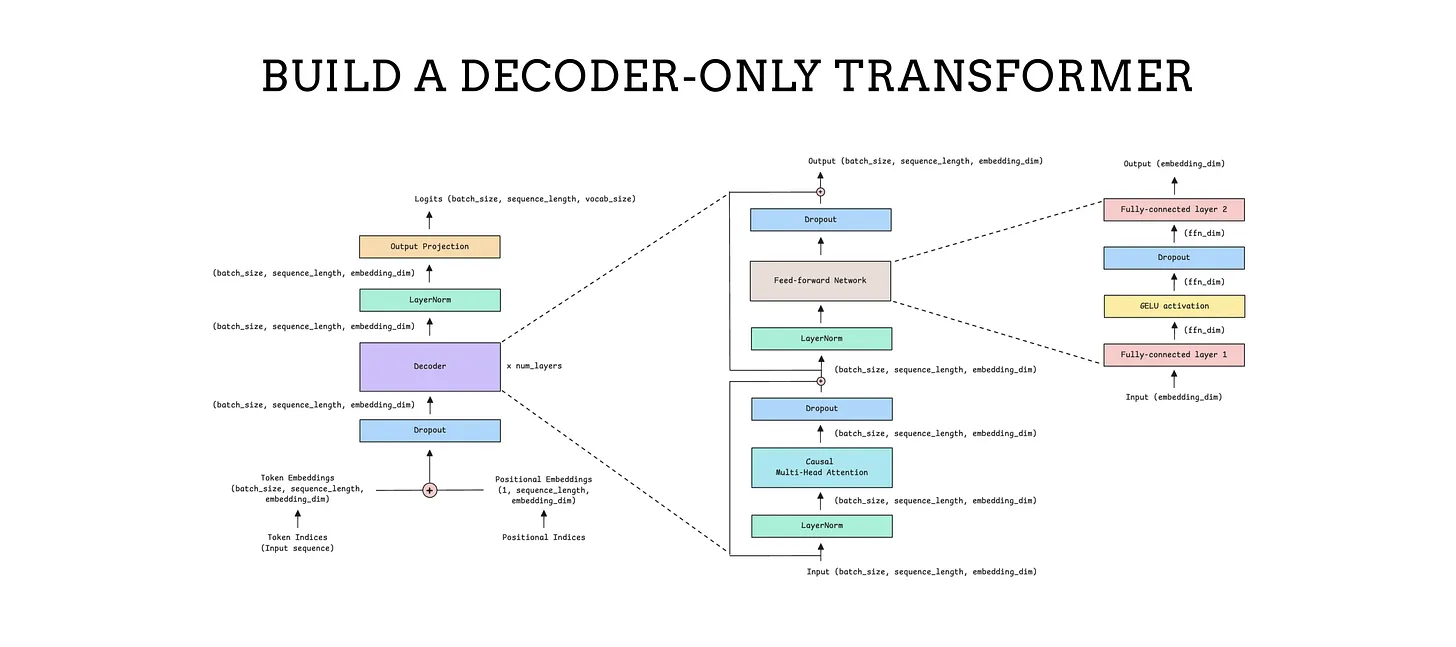

https://www.intoai.pub/p/build-a-decoder-only-transformer

In [26]:
# Constants for the dataset and model
FAMILIES = ("AcyP", "HPr", "HU")
AA = "ACDEFGHIKLMNPQRSTVWY"
special_tokens = ["<PAD>", "<BOS>", "<EOS>"]
total_tokens = list(special_tokens) + list(AA)
IGNORE_INDEX = -1  # what F.cross_entropy(ignore_index=...) must be given for the generative task

In [62]:
from protgen.data import ProteinDataset
from torch.utils.data import DataLoader

train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

print(f"Data class: {train_data}")

# Get tensors
X_train = train_data.tokens
y_train_labels = train_data.labels          # classification task
y_train_shifted = train_data.tokens_shifted # generative task

print(f"# Train data: \n Tokens shape: {X_train.shape}\n Labels (shape): {y_train_labels.shape} \n Shifted shape: {y_train_shifted.shape}")


# Indexing
x, x_shifted, y, length = train_data[0]
print(f"# Sample 0: \nTokens: \n {x}\n Shifted: \n {x_shifted}\n Label: {y}\n Length: {length}")

# DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

Data class: ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129)
# Train data: 
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020]) 
 Shifted shape: torch.Size([16020, 129])
# Sample 0: 
Tokens: 
 tensor([ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
         3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
        22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
        13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
         5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
        10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0])
 Shifted: 
 tensor([13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
        19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22

In [63]:
import torch
import pandas as pd
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
import torch.nn as nn

# test data
# input: 2 samples, sequence of tokens
example_protein_seq_data = torch.stack([train_data[0][0], train_data[1][0]])

y = torch.stack([train_data[0][1], train_data[1][1]])

example_protein_seq_data


tensor([[ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
          3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
         22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
         13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
          5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
         10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0,  0],
        [ 1, 13, 14, 11,  9,  6, 12, 10, 19, 17, 10, 18,  6, 11, 18,  8, 13, 19,
         11, 11,  5, 20,  6, 18, 20, 12, 14,  8,  7, 13,  5,  6, 20, 19,  5,  3,
         12,  8, 18,  8, 14, 11, 20, 16, 12, 10,  8,  7,  8, 19,  7,  6, 19, 17,
         11, 17, 18, 16, 17, 14,  8, 17, 14, 15, 16, 19,  8,  5, 19, 10, 19, 10,
         15,  3, 18, 19, 10, 15,  3,  7, 11,  3,  8, 18, 17, 12, 11,  8,  3, 20,
      

In [ ]:
# TRUE output: shifted
# ignore_index = -1 (for loss function)
y

tensor([[13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
         19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22,
         16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10, 13,
         18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,  5,
          6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12, 10,
         14, 22,  2, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1],
        [13, 14, 11,  9,  6, 12, 10, 19, 17, 10, 18,  6, 11, 18,  8, 13, 19, 11,
         11,  5, 20,  6, 18, 20, 12, 14,  8,  7, 13,  5,  6, 20, 19,  5,  3, 12,
          8, 18,  8, 14, 11, 20, 16, 12, 10,  8,  7,  8, 19,  7,  6, 19, 17, 11,
         17, 18, 16, 17, 14,  8, 17, 14, 15, 16, 19,  8,  5, 19, 10, 19, 10, 15,
          3, 18, 19, 10, 15,  3,  7, 11,  3,  8, 18, 17, 12, 11,  8,  3, 20, 11,
      

In [57]:
example_protein_seq_data.shape, y.shape

(torch.Size([2, 129]), torch.Size([]))

In [28]:
train_data.vocab, train_data.vocab_size

({'<PAD>': 0,
  '<BOS>': 1,
  '<EOS>': 2,
  'A': 3,
  'C': 4,
  'D': 5,
  'E': 6,
  'F': 7,
  'G': 8,
  'H': 9,
  'I': 10,
  'K': 11,
  'L': 12,
  'M': 13,
  'N': 14,
  'P': 15,
  'Q': 16,
  'R': 17,
  'S': 18,
  'T': 19,
  'V': 20,
  'W': 21,
  'Y': 22},
 23)

Starting with causal multi-head self attention

adapted from https://docs.pytorch.org/tutorials/intermediate/scaled_dot_product_attention_tutorial.html#causal-self-attention

attn_mask = True -> values that participate in self attention

In [51]:
import torch
import torch.nn as nn
import torch.nn.functional as F
device = "cuda" if torch.cuda.is_available() else "cpu"

batch_size = 2 # for now 
seq_len = 129 

embed_dim = 128 # this is 128 / 4 = 32 per head, altogether almost as seq_len (positional qualities per residue??)
num_heads= 4
pad_idx=0


# i need to combine causal and padding mask
# causal mask = -inf for upper right triangle
# padding mask = -inf for all padding tokens (0) 
# attn_mask (true, false) -> the ones that are false are not being part of attention
# need to put the upper left triangle that is still true to false in the attn mask to make it causal as well
# hooooowwwwww ???????????

# Q, K, V shapes: (batch_size, num_heads, seq_len, head_dim) 
# attention scores shape: (batch_size, num_heads, seq_len, seq_len)
# mask shape: (batch_size, 1 (broadcasts to num_heads), seq_len, seq_len)

# causal mask is just diagional upper right triangle False, lower left and diagonal True
# padding mask i need to look for padding tokens in input sequence (when the sequence is done before max length)





# adapted from https://docs.pytorch.org/tutorials/intermediate/scaled_dot_product_attention_tutorial.html#causal-self-attention
class CausalSelfAttention(nn.Module):

    # doesn't have is_causal because we also have padding so need to combine causal + padding mask 
    
    def __init__(self, num_heads: int, embed_dimension: int, pad_idx: int, bias: bool=False, dropout:float=0.0):
        
        
        super().__init__()
        assert embed_dimension % num_heads == 0
        
        # ADDED: 
        # starts with LayerNorm
        self.ln_1 = nn.LayerNorm(embed_dimension)
        
        
        # key, query, value projections for all heads, but in a batch
        self.c_attn = nn.Linear(embed_dimension, 3 * embed_dimension, bias=bias)
        
        # output projection
        self.c_proj = nn.Linear(embed_dimension, embed_dimension, bias=bias)
        
        # regularization
        self.dropout = dropout
        self.resid_dropout = nn.Dropout(dropout)
        self.num_heads = num_heads
        self.embed_dimension = embed_dimension
        self.pad_idx = pad_idx
        self.head_dim = embed_dimension // num_heads
        
        
        

    def forward(self, x):
        
        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        query_projected = self.c_attn(x)

        batch_size = query_projected.size(0)
        seq_len = query_projected.size(1)
        embed_dim = query_projected.size(2)
        head_dim = embed_dim // (self.num_heads * 3)

        # separate query, key, value and reshape for multi-head attention
        query, key, value = query_projected.chunk(3, -1)
        # reshape to (batch_size, num_heads, seq_len, head_dim)
        query = query.view(batch_size, -1, self.num_heads, self.head_dim).transpose(1, 2)
        key = key.view(batch_size, -1, self.num_heads, self.head_dim).transpose(1, 2)
        value = value.view(batch_size, -1, self.num_heads, self.head_dim).transpose(1, 2)

        # noww masks
        
        # https://docs.pytorch.org/docs/2.15/generated/torch.tril.html
        causal_mask = torch.tril(torch.ones(seq_len, seq_len)).unsqueeze(0).unsqueeze(1)  # shape is now (1, 1, seq_len, seq_len)
        # have to change it to boolean mask
        causal_mask = causal_mask.bool()
        # shape of x is (batch_size, seq_len, embed_dim) 
        # boolean mask: shape of x -> remove last dim -> unsqueeze twice
        padding_mask = (x != self.pad_idx).any(dim=-1).unsqueeze(1).unsqueeze(2)  # shape is now (batch_size, 1, 1, seq_len)
        
        # FINAL MASK
        attn_mask = causal_mask & padding_mask  # shape is now (batch_size, 1, seq_len, seq_len)
        print(causal_mask.shape, padding_mask.shape, attn_mask.shape)
        
        
        print("Causal mask: ", causal_mask)
        print("Padding mask: ", padding_mask)
        print("Attention mask: ", attn_mask)        
        

        y = F.scaled_dot_product_attention(query, key, value, 
                                           attn_mask=attn_mask, 
                                           dropout_p=self.dropout, 
                                           is_causal=False)
        
        y = y.transpose(1, 2).view(batch_size, -1, self.num_heads * head_dim)

        y = self.resid_dropout(self.c_proj(y))
        return y







In [ ]:
# TEST

short_example = example_protein_seq_data[:,:10].clone()  # take first 10 tokens of each sample  
short_example[0, 5:] = 0  # fake padding
short_example[1, 8:] = 0 
print(f"Short example shape: {short_example.shape}")
print(f"Short example: {short_example}")

embedding_layer = nn.Embedding(train_data.vocab_size, embed_dim, padding_idx=pad_idx)
x = embedding_layer(short_example)
csa = CausalSelfAttention(num_heads=num_heads, embed_dimension=embed_dim, pad_idx=pad_idx, dropout=0.0)
output = csa.forward(x)
print(f"Output shape: {output.shape}")
print(f"Output: {output}")

# looks correct to me!!


Short example shape: torch.Size([2, 10])
Short example: tensor([[ 1, 13, 10, 11, 11,  0,  0,  0,  0,  0],
        [ 1, 13, 14, 11,  9,  6, 12, 10,  0,  0]])
torch.Size([1, 1, 10, 10]) torch.Size([2, 1, 1, 10]) torch.Size([2, 1, 10, 10])
Causal mask:  tensor([[[[ True, False, False, False, False, False, False, False, False, False],
          [ True,  True, False, False, False, False, False, False, False, False],
          [ True,  True,  True, False, False, False, False, False, False, False],
          [ True,  True,  True,  True, False, False, False, False, False, False],
          [ True,  True,  True,  True,  True, False, False, False, False, False],
          [ True,  True,  True,  True,  True,  True, False, False, False, False],
          [ True,  True,  True,  True,  True,  True,  True, False, False, False],
          [ True,  True,  True,  True,  True,  True,  True,  True, False, False],
          [ True,  True,  True,  True,  True,  True,  True,  True,  True, False],
          [